# 06 – Profit Analysis
Goal: answer the business questions from the Project Charter in money terms – where the company loses margin on delivery,
which routes and product lines are the least efficient, and which levers add the most profit per year.

- Base rate table: USPS Ground Advantage commercial; UPS Ground used as a check.
- Yearly values = 4 years of data (2021–2024) / 4.
- Dollar amounts are illustrative (formula-based carrier prices); proportions and directions are reliable.

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

P = "../data/processed/"
sales = pd.read_csv(P + "sales.csv", dtype={"postal_code": str})
products = pd.read_csv(P + "products.csv")
factories = pd.read_csv(P + "factories.csv")
zips = pd.read_csv(P + "zips.csv", dtype={"zip": str})
road = pd.read_csv(P + "road_distances.csv", dtype={"zip": str})
formulas = pd.read_csv(P + "cost_formulas.csv", index_col="variant")
orders = pd.read_csv(P + "orders_scenarios.csv", dtype={"postal_code": str})

YEARS = 4                    # data covers 2021–2024 → yearly values = total / 4
BASE = "usps_commercial"     # base rate table; UPS Ground used as a check
fees = {v: orders[f"current_cost_{v}"].mean() for v in formulas.index}
fee = fees[BASE]

lines = sales.merge(products[["product_id", "factory"]], on="product_id")
lines["order_no"] = lines["order_id"].str.rsplit("-", n=3).str[0]

def haversine_miles(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 3958.8 * 2 * np.arcsin(np.sqrt(a))

pairs = zips.merge(factories, how="cross")
pairs["straight_miles"] = haversine_miles(pairs["lat"], pairs["lng"], pairs["latitude"], pairs["longitude"])
road_wide = road.pivot(index="zip", columns="factory", values="road_miles")
# Lookups (ZIP, factory) → miles
road_long = road.set_index(["zip", "factory"])["road_miles"]
straight_long = pairs.set_index(["zip", "factory"])["straight_miles"]

def parcels_from(lines_df, factory_col):
    """Group order lines into parcels (order × factory) and price them with both rate tables (same model as notebook 04)."""
    p = (lines_df.groupby(["order_no", factory_col], as_index=False)
                 .agg(postal_code=("postal_code", "first"), units=("units", "sum"), sales=("sales", "sum"))
                 .rename(columns={factory_col: "factory"}))
    p["billable_lb"] = np.ceil(p["units"] * 2 / 16 + 0.5)
    key = pd.MultiIndex.from_arrays([p["postal_code"], p["factory"]])
    p["road_miles"] = road_long.reindex(key).values
    p["straight_miles"] = straight_long.reindex(key).values
    for v, f in formulas.iterrows():
        p[f"cost_{v}"] = (f["a"] + f["b"] * p["billable_lb"] + f["c"] * p["straight_miles"]
                          + f["e"] * p["billable_lb"] * p["straight_miles"])
    return p

parcels = parcels_from(lines, "factory")
assert abs(parcels[f"cost_{BASE}"].sum() - orders[f"current_cost_{BASE}"].sum()) < 0.01   # same as notebook 04

gross_profit_year = orders["gross_profit"].sum() / YEARS
print("Delivery fee per order:", {v: round(x, 2) for v, x in fees.items()})
print(f"Orders: {len(orders)} | parcels (current): {len(parcels)} | gross profit per year: ${gross_profit_year:,.0f}")

Delivery fee per order: {'usps_commercial': np.float64(14.28), 'ups_ground': np.float64(20.94)}
Orders: 5009 | parcels (current): 6825 | gross profit per year: $22,877


## Q1. Where does the company lose money on delivery?
Delivery result per order = customer fee − carrier cost. Margin after delivery = gross profit + delivery result.
Orders are compared by size, number of parcels and distance.

In [10]:
orders["delivery_result"] = fee - orders[f"current_cost_{BASE}"]
orders["margin_after_delivery"] = orders["gross_profit"] + orders["delivery_result"]
orders["miles_per_parcel"] = orders["current_road_miles"] / orders["current_parcels"]

orders["size_band"] = pd.cut(orders["units"], [0, 2, 4, 6, 9, 100], labels=["1–2", "3–4", "5–6", "7–9", "10+"])
orders["parcels_band"] = orders["current_parcels"].clip(upper=3).map({1: "1", 2: "2", 3: "3+"})
orders["distance_band"] = pd.cut(orders["miles_per_parcel"], [0, 500, 1000, 1500, 2000, 4000],
                                 labels=["<500", "500–1000", "1000–1500", "1500–2000", "2000+"])

def profile(df, group_col):
    """Delivery economics per group: averages per order, yearly delivery result, margin after delivery."""
    g = df.groupby(group_col, observed=True).agg(
        orders=("sales", "size"),
        avg_sales=("sales", "mean"),
        avg_gross_profit=("gross_profit", "mean"),
        avg_shipping_cost=(f"current_cost_{BASE}", "mean"),
        avg_delivery_result=("delivery_result", "mean"),
        delivery_result_total=("delivery_result", "sum"),
        margin_total=("margin_after_delivery", "sum"),
        sales_total=("sales", "sum"),
        cost_above_fee_pct=("delivery_result", lambda x: (x < 0).mean() * 100),
    )
    g["orders_pct"] = g["orders"] / g["orders"].sum() * 100
    g["delivery_result_per_year"] = g["delivery_result_total"] / YEARS
    g["margin_after_delivery_pct"] = g["margin_total"] / (g["sales_total"] + fee * g["orders"]) * 100
    return g[["orders", "orders_pct", "avg_sales", "avg_gross_profit", "avg_shipping_cost", "avg_delivery_result",
              "delivery_result_per_year", "cost_above_fee_pct", "margin_after_delivery_pct"]].round(1)

print("By order size (units):"); display(profile(orders, "size_band"))
print("By number of parcels per order:"); display(profile(orders, "parcels_band"))
print("By distance – single-parcel orders only (removes the effect of split shipments):")
display(profile(orders[orders["current_parcels"] == 1], "distance_band"))

print(f"Correlation of margin after delivery with order value: {orders['margin_after_delivery'].corr(orders['sales']):.2f}, "
      f"with miles per parcel: {orders['margin_after_delivery'].corr(orders['miles_per_parcel']):.2f}")

By order size (units):


,orders,orders_pct,avg_sales,avg_gross_profit,avg_shipping_cost,avg_delivery_result,delivery_result_per_year,cost_above_fee_pct,margin_after_delivery_pct
size_band,,,,,,,,,
1–2,853,17.0,6.2,4.1,9.7,4.6,984.6,0.7,42.5
3–4,1069,21.3,12.4,8.2,10.5,3.8,1021.7,8.6,45.1
5–6,837,16.7,19.6,13.0,13.3,1.0,203.4,25.8,41.3
7–9,908,18.1,28.5,18.8,15.0,-0.7,-169.3,41.1,42.1
10+,1342,26.8,58.1,38.2,20.4,-6.1,-2040.3,79.4,44.4


By number of parcels per order:


,orders,orders_pct,avg_sales,avg_gross_profit,avg_shipping_cost,avg_delivery_result,delivery_result_per_year,cost_above_fee_pct,margin_after_delivery_pct
parcels_band,,,,,,,,,
1,3320,66.3,18.2,12.1,10.4,3.9,3211.0,1.9,49.3
2,1570,31.3,43.6,29.0,21.1,-6.9,-2696.8,100.0,38.2
3+,119,2.4,83.2,47.8,31.6,-17.3,-514.2,100.0,31.3


By distance – single-parcel orders only (removes the effect of split shipments):


,orders,orders_pct,avg_sales,avg_gross_profit,avg_shipping_cost,avg_delivery_result,delivery_result_per_year,cost_above_fee_pct,margin_after_delivery_pct
distance_band,,,,,,,,,
<500,462,13.9,17.8,11.9,8.4,5.9,678.5,0.0,55.3
500–1000,866,26.1,17.8,11.7,9.2,5.1,1101.5,0.0,52.2
1000–1500,484,14.6,18.1,12.1,9.9,4.4,526.6,0.0,50.8
1500–2000,449,13.5,19.5,13.0,11.0,3.3,371.9,1.1,48.4
2000+,1059,31.9,18.2,12.3,12.3,2.0,532.5,5.6,44.0


Correlation of margin after delivery with order value: 0.93, with miles per parcel: -0.09


**Findings:**
- **Split shipments are the main source of delivery losses.** One third of orders (1,689) ship as 2+ parcels for one fee:
  they lose $3,211 per year on delivery (−$6.9 per order with 2 parcels, −$17.3 with 3+), and their margin after delivery
  is 38.2% / 31.3% vs 49.3% for single-parcel orders. Single-parcel orders earn exactly what split orders lose.
- **Distance alone does not create losses.** Among single-parcel orders delivery is profitable in every distance band
  (+$5.9 per order under 500 mi, +$2.0 over 2,000 mi); only 5.6% of the longest orders cost more than the fee.
  Distance lowers the margin (55% → 44%) but is not the loss driver.
- **Small orders are not unprofitable.** Orders of 1–4 units have a margin after delivery of 42–45%, the same as large orders,
  and even earn on delivery. Large orders (10+ units) lose $6.1 on delivery (heavier, more often split) but bring the most
  profit in dollars. This corrects the earlier assumption (under the "company pays all shipping" model) that small orders are the problem.
- Margin after delivery in dollars follows order value (correlation 0.93), not distance (−0.09).

**Sanity check:**
- 100% of multi-parcel orders cost more than the fee – plausible: two parcels cost at least ~2 × $7.50 = $15 > fee $14.28.
- Yearly delivery results add up to zero (3,211 − 2,697 − 514 = 0): correct, because the fee equals the average cost by construction.
- Does "distance does not create losses" contradict the scenario savings, 47% of which come from fewer miles? No – distance
  raises the cost per parcel ($8.4 → $12.3) and those savings are real money, but on single-parcel orders it rarely pushes the cost above the fee.

## Q3. Which product lines have the best margin – before and after delivery?
Parcel cost is allocated to order lines by units (weight driver); the order's fee is allocated to its lines by sales value.

In [11]:
# Allocate each parcel's carrier cost to its lines by units (weight driver)
# and each order's fee to its lines by sales value
alloc = lines.merge(parcels[["order_no", "factory", "units", f"cost_{BASE}"]].rename(columns={"units": "parcel_units"}),
                    on=["order_no", "factory"])
alloc["shipping_cost"] = alloc[f"cost_{BASE}"] * alloc["units"] / alloc["parcel_units"]
alloc["fee_share"] = fee * alloc["sales"] / alloc.groupby("order_no")["sales"].transform("sum")
assert abs(alloc["shipping_cost"].sum() - parcels[f"cost_{BASE}"].sum()) < 0.01

def margins(group_cols):
    g = alloc.groupby(group_cols).agg(units=("units", "sum"), sales=("sales", "sum"), gross_profit=("gross_profit", "sum"),
                                      fee=("fee_share", "sum"), shipping_cost=("shipping_cost", "sum"))
    g["gross_margin_pct"] = g["gross_profit"] / g["sales"] * 100
    g["margin_after_delivery_pct"] = (g["gross_profit"] + g["fee"] - g["shipping_cost"]) / (g["sales"] + g["fee"]) * 100
    g["profit_after_delivery_per_year"] = (g["gross_profit"] + g["fee"] - g["shipping_cost"]) / YEARS
    return g.drop(columns=["fee", "shipping_cost"]).sort_values("margin_after_delivery_pct", ascending=False).round(1)

display(margins(["division"]))
display(margins(["division", "factory", "product_name"]))

,units,sales,gross_profit,gross_margin_pct,margin_after_delivery_pct,profit_after_delivery_per_year
division,,,,,,
Chocolate,36508,129019.6,87030.0,67.5,44.3,21891.3
Other,1228,9383.2,4193.4,44.7,31.7,929.7
Sugar,137,427.5,284.7,66.6,30.1,56.1


units    sales  \
division  factory           product_name                                        
Sugar     Secret Factory    Everlasting Gobstopper                13    130.0   
          The Other Factory Hair Toffee                           17     76.5   
Chocolate Lot's O' Nuts     Wonka Bar - Nutty Crunch Surprise   6664  23257.4   
                            Wonka Bar -Scrumdiddlyumptious      7563  27226.8   
Other     Secret Factory    Lickable Wallpaper                   379   7580.0   
Chocolate Lot's O' Nuts     Wonka Bar - Fudge Mallows           6792  24451.2   
          Wicked Choccy's   Wonka Bar - Triple Dazzle Caramel   7490  28087.5   
                            Wonka Bar - Milk Chocolate          7999  25996.8   
Sugar     Sugar Shack       Fizzy Lifting Drinks                  21     78.8   
                            Laffy Taffy                           27     53.7   
                            SweeTARTS                             41     61.5   
                            Fun Dip                                8     12.0   
Other     The Other Factory Kazookles                            371   1205.8   
          Secret Factory    Wonka Gum                            478    597.5   
Sugar     Sugar Shack       Nerds                                 10     15.0   

                                                               gross_profit  \
division  factory           product_name                                      
Sugar     Secret Factory    Everlasting Gobstopper                    104.0   
          The Other Factory Hair Toffee                                59.5   
Chocolate Lot's O' Nuts     Wonka Bar - Nutty Crunch Surprise       16593.4   
                            Wonka Bar -Scrumdiddlyumptious          18907.5   
Other     Secret Factory    Lickable Wallpaper                       3790.0   
Chocolate Lot's O' Nuts     Wonka Bar - Fudge Mallows               16300.8   
          Wicked Choccy's   Wonka Bar - Triple Dazzle Caramel       18350.5   
                            Wonka Bar - Milk Chocolate              16877.9   
Sugar     Sugar Shack       Fizzy Lifting Drinks                       47.2   
                            Laffy Taffy                                33.5   
                            SweeTARTS                                  28.7   
                            Fun Dip                                     4.8   
Other     The Other Factory Kazookles                                  92.8   
          Secret Factory    Wonka Gum                                 310.7   
Sugar     Sugar Shack       Nerds                                       7.0   

                                                               gross_margin_pct  \
division  factory           product_name                                          
Sugar     Secret Factory    Everlasting Gobstopper                         80.0   
          The Other Factory Hair Toffee                                    77.8   
Chocolate Lot's O' Nuts     Wonka Bar - Nutty Crunch Surprise              71.3   
                            Wonka Bar -Scrumdiddlyumptious                 69.4   
Other     Secret Factory    Lickable Wallpaper                             50.0   
Chocolate Lot's O' Nuts     Wonka Bar - Fudge Mallows                      66.7   
          Wicked Choccy's   Wonka Bar - Triple Dazzle Caramel              65.3   
                            Wonka Bar - Milk Chocolate                     64.9   
Sugar     Sugar Shack       Fizzy Lifting Drinks                           60.0   
                            Laffy Taffy                                    62.3   
                            SweeTARTS                                      46.7   
                            Fun Dip                                        40.0   
Other     The Other Factory Kazookles                                       7.7   
          Secret Factory    Wonka Gum                                      52.0   
Sugar     Sug

## Q2. Which factory → customer routes are the most and least efficient?
Route = factory → customer state. Efficiency = shipping cost as % of sales on the route (how much of each sales dollar goes to the carrier).
Excess miles = route miles − miles from the nearest factory that makes the same division. Only routes with at least 40 parcels are ranked.

In [12]:
# Excess miles = route miles − miles from the nearest factory making the same division
division_factories = products.groupby("division")["factory"].unique().apply(list).to_dict()
parcels = parcels.merge(lines.groupby(["order_no", "factory"])["division"].first().reset_index(), on=["order_no", "factory"])
parcels["nearest_miles"] = [road_wide.loc[z, division_factories[d]].min()
                            for z, d in zip(parcels["postal_code"], parcels["division"])]
parcels["excess_miles"] = parcels["road_miles"] - parcels["nearest_miles"]
parcels = parcels.merge(zips[["zip", "state_id"]], left_on="postal_code", right_on="zip").drop(columns="zip")

routes = parcels.groupby(["factory", "state_id"]).agg(
    parcels=("order_no", "size"), sales=("sales", "sum"), avg_road_miles=("road_miles", "mean"),
    avg_excess_miles=("excess_miles", "mean"), shipping_cost=(f"cost_{BASE}", "sum"))
routes["cost_per_parcel"] = routes["shipping_cost"] / routes["parcels"]
routes["cost_pct_of_sales"] = routes["shipping_cost"] / routes["sales"] * 100
routes["cost_per_year"] = routes["shipping_cost"] / YEARS

main_routes = routes[routes["parcels"] >= 40].sort_values("cost_pct_of_sales")
print(f"Routes: {len(routes)}; with at least 40 parcels: {len(main_routes)} "
      f"({main_routes['parcels'].sum() / routes['parcels'].sum() * 100:.0f}% of parcels)")
print("Most efficient routes (lowest shipping cost as % of sales):"); display(main_routes.head(5).round(1))
print("Least efficient routes:"); display(main_routes.tail(5).round(1))
print(f"Correlation of cost % of sales with route miles: {main_routes['cost_pct_of_sales'].corr(main_routes['avg_road_miles']):.2f}")
print(f"Excess miles: {parcels['excess_miles'].sum() / parcels['road_miles'].sum() * 100:.1f}% of all miles driven today")

Routes: 177; with at least 40 parcels: 36 (81% of parcels)
Most efficient routes (lowest shipping cost as % of sales):


parcels    sales  avg_road_miles  avg_excess_miles  \
factory         state_id                                                       
Lot's O' Nuts   CO             58   1447.7           815.4               0.0   
                AZ             77   1468.0            72.9               0.0   
                CA            718  15044.9           557.5               0.0   
                OR             46   1085.9          1318.8               0.0   
Wicked Choccy's VA             72   1490.0           516.9               0.0   

                          shipping_cost  cost_per_parcel  cost_pct_of_sales  \
factory         state_id                                                      
Lot's O' Nuts   CO                538.2              9.3               37.2   
                AZ                607.3              7.9               41.4   
                CA               6368.6              8.9               42.3   
                OR                461.6             10.0               42.5   
Wicked Choccy's VA                635.3              8.8               42.6   

                          cost_per_year  
factory         state_id                 
Lot's O' Nuts   CO                134.5  
                AZ                151.8  
                CA               1592.2  
                OR                115.4  
Wicked Choccy's VA                158.8

Least efficient routes:


parcels    sales  avg_road_miles  avg_excess_miles  \
factory         state_id                                                       
Lot's O' Nuts   MA             47   1003.2          2721.2            1696.3   
                FL            138   2640.1          2149.5            1795.1   
                NJ             43    825.9          2421.0            1627.7   
Wicked Choccy's CA            594  11394.0          2522.0            1963.5   
                WA            159   3023.0          2876.7            1406.2   

                          shipping_cost  cost_per_parcel  cost_pct_of_sales  \
factory         state_id                                                      
Lot's O' Nuts   MA                608.8             13.0               60.7   
                FL               1616.4             11.7               61.2   
                NJ                532.9             12.4               64.5   
Wicked Choccy's CA               7494.8             12.6               65.8   
                WA               2068.9             13.0               68.4   

                          cost_per_year  
factory         state_id                 
Lot's O' Nuts   MA                152.2  
                FL                404.1  
                NJ                133.2  
Wicked Choccy's CA               1873.7  
                WA                517.2

Correlation of cost % of sales with route miles: 0.79
Excess miles: 47.1% of all miles driven today


**Findings:**
- Chocolate is the whole business: 93% of sales and 96% of profit after delivery ($21.9k of $22.9k per year), margin after delivery 44%.
- The two weakest bars are the only products of Wicked Choccy's (Georgia): Milk Chocolate 39.9% and Triple Dazzle Caramel 42.8%,
  vs ~47% for Nutty Crunch and Scrumdiddlyumptious from Lot's O' Nuts (Arizona) – they often travel to California and often share an order with Arizona bars (split shipments).
- Four products are negative after delivery: Kazookles (gross margin only 7.7%: price $3.25 vs cost $3.00), Wonka Gum (low price, $1.25),
  Nerds and Fun Dip. Together about −$47 per year → a pricing issue rather than a logistics one.

**Sanity check:** the result for cheap products depends on the allocation rule – the fee is split by sales value, so a $1.25 item
gets a small share of the fee but a full share of the parcel weight. Kazookles is negative under any rule (7.7% gross margin cannot absorb shipping).
Sugar has only 137 units in four years → its percentages are not reliable.

**Findings:**
- Most efficient routes: customers close to the right factory – Lot's O' Nuts (Arizona) → CO, AZ, CA, OR and Wicked Choccy's (Georgia) → VA:
  37–43% of sales goes to the carrier, zero excess miles.
- Least efficient: coast to coast – Wicked Choccy's → CA, WA and Lot's O' Nuts → MA, FL, NJ: 61–68% of sales, 1,400–2,000 excess miles per parcel.
- Largest single route by money: Wicked Choccy's (Georgia) → California, $1,874 shipping cost per year – while the other chocolate factory is in neighbouring Arizona.
- 47% of all miles driven today are excess miles.

**Sanity check:** on routes, cost as % of sales correlates with distance (0.79), while at order level margin barely correlates with distance (−0.09).
No contradiction: route averages remove order-size noise and show the cost effect of distance; at order level, dollar margin is driven by order value.

## Map: where the company gains and loses on delivery

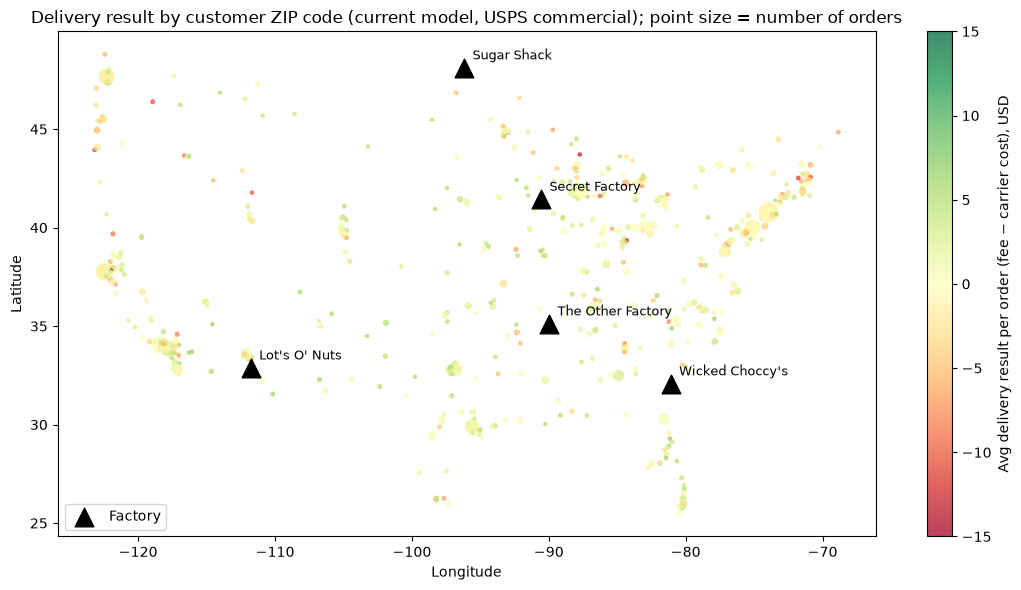

In [13]:
by_zip = (orders.groupby("postal_code")
                .agg(orders=("sales", "size"), delivery_result=("delivery_result", "mean"))
                .join(zips.set_index("zip")[["lat", "lng"]]))
by_zip = by_zip[(by_zip["lng"] > -125) & (by_zip["lat"] < 50)]          # contiguous US (drops AK/HI if any)

fig, ax = plt.subplots(figsize=(11, 6))
points = ax.scatter(by_zip["lng"], by_zip["lat"], c=by_zip["delivery_result"], s=10 + by_zip["orders"] * 1.5,
                    cmap="RdYlGn", vmin=-15, vmax=15, alpha=0.75, edgecolors="none")
ax.scatter(factories["longitude"], factories["latitude"], marker="^", s=180, c="black", label="Factory")
for _, f in factories.iterrows():
    ax.annotate(f["factory"], (f["longitude"], f["latitude"]), xytext=(6, 6), textcoords="offset points", fontsize=9)
fig.colorbar(points, ax=ax, label="Avg delivery result per order (fee − carrier cost), USD")
ax.set_title("Delivery result by customer ZIP code (current model, USPS commercial); point size = number of orders")
ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude"); ax.legend(loc="lower left")
plt.tight_layout()
plt.show()

**Findings:** gains and losses are scattered across the country rather than concentrated in one region – consistent with Q1:
the loss driver is split shipments (an order-level problem), not geography alone. Losses (red) appear both near and far from factories.

## Q4. Which product lines should be moved to a different factory?
Simulation: each product keeps one factory (today's rule), but the factory can change. First every product is moved alone to every
other factory; then a greedy plan applies the best move, recalculates and repeats until no move saves at least $50 per year.

In [14]:
def total_cost(assign, variant=BASE):
    """Yearly shipping cost when each product is made in the factory given by assign[product_id]."""
    sim = parcels_from(lines.assign(sim_factory=lines["product_id"].map(assign)), "sim_factory")
    return sim[f"cost_{variant}"].sum() / YEARS

current_assign = dict(zip(products["product_id"], products["factory"]))
base = total_cost(current_assign)

# 1) Each product moved alone to every other factory
single = pd.DataFrame([
    {"product_id": pid, "to_factory": fac, "saving_per_year": base - total_cost({**current_assign, pid: fac})}
    for pid in products["product_id"] for fac in factories["factory"] if fac != current_assign[pid]])
best_single = (single.loc[single.groupby("product_id")["saving_per_year"].idxmax()]
               .merge(products[["product_id", "division", "product_name", "factory"]], on="product_id")
               .sort_values("saving_per_year", ascending=False))
print("Best single move per product ($ per year):")
display(best_single[["division", "product_name", "factory", "to_factory", "saving_per_year"]].round(0))

# 2) Greedy: apply the best move, recompute all moves, repeat until no move saves at least $50 per year
assign, steps = dict(current_assign), []
while True:
    current = total_cost(assign)
    gain, pid, fac = max((current - total_cost({**assign, p: f}), p, f)
                         for p in products["product_id"] for f in factories["factory"] if f != assign[p])
    if gain < 50:
        break
    assign[pid] = fac
    steps.append({"step": len(steps) + 1, "product": products.set_index("product_id").at[pid, "product_name"],
                  "to_factory": fac, "gain_per_year": round(gain)})
print("Greedy relocation plan:"); display(pd.DataFrame(steps))

relocated = parcels_from(lines.assign(sim_factory=lines["product_id"].map(assign)), "sim_factory")
for v in formulas.index:
    print(f"{v}: saving ${total_cost(current_assign, v) - total_cost(assign, v):,.0f} per year")
print(f"Parcels: {len(parcels)} → {len(relocated)} | road miles: "
      f"{(relocated['road_miles'].sum() / parcels['road_miles'].sum() - 1) * 100:+.1f}%")
volume = pd.DataFrame({"units_now": lines.groupby("factory")["units"].sum(),
                       "units_after": lines.assign(f=lines["product_id"].map(assign)).groupby("f")["units"].sum()}).fillna(0)
volume["change_pct"] = (volume["units_after"] / volume["units_now"] - 1) * 100
display(volume.round(0))

Best single move per product ($ per year):


,division,product_name,factory,to_factory,saving_per_year
1,Chocolate,Wonka Bar - Milk Chocolate,Wicked Choccy's,Lot's O' Nuts,1066.0
4,Chocolate,Wonka Bar - Triple Dazzle Caramel,Wicked Choccy's,Lot's O' Nuts,996.0
3,Chocolate,Wonka Bar -Scrumdiddlyumptious,Lot's O' Nuts,Wicked Choccy's,329.0
0,Chocolate,Wonka Bar - Fudge Mallows,Lot's O' Nuts,Wicked Choccy's,223.0
2,Chocolate,Wonka Bar - Nutty Crunch Surprise,Lot's O' Nuts,Wicked Choccy's,195.0
6,Other,Wonka Gum,Secret Factory,Wicked Choccy's,126.0
8,Other,Lickable Wallpaper,Secret Factory,Lot's O' Nuts,119.0
7,Other,Kazookles,The Other Factory,Lot's O' Nuts,116.0
14,Sugar,SweeTARTS,Sugar Shack,Lot's O' Nuts,10.0
5,Other,Fizzy Lifting Drinks,Sugar Shack,Lot's O' Nuts,8.0


Greedy relocation plan:


,step,product,to_factory,gain_per_year
0,1,Wonka Bar - Milk Chocolate,Lot's O' Nuts,1066
1,2,Wonka Bar - Triple Dazzle Caramel,Lot's O' Nuts,2424
2,3,Wonka Gum,Lot's O' Nuts,160
3,4,Lickable Wallpaper,Lot's O' Nuts,140
4,5,Kazookles,Lot's O' Nuts,140


usps_commercial: saving $3,930 per year
ups_ground: saving $6,272 per year
Parcels: 6825 → 5035 | road miles: -20.8%


,units_now,units_after,change_pct
Lot's O' Nuts,21019,37736.0,80.0
Secret Factory,870,13.0,-99.0
Sugar Shack,107,107.0,0.0
The Other Factory,388,17.0,-96.0
Wicked Choccy's,15489,0.0,-100.0


**Findings:**
- Best single move: Milk Chocolate from Wicked Choccy's (Georgia) to Lot's O' Nuts (Arizona) – $1,066 per year;
  after it, moving Triple Dazzle Caramel as well adds $2,424 – together they put all chocolate in one factory, so chocolate orders ship as one parcel.
- The greedy plan ends with almost everything made in Lot's O' Nuts: saving $3,930 per year (USPS) / $6,272 (UPS),
  parcels 6,825 → 5,035, road miles −21%. Moving the small Other products adds only ~$440 per year.
- Cost of this option: Lot's O' Nuts would need +80% capacity and Wicked Choccy's would have no products left.

**Sanity check:** why would shipping chocolate from Arizona to the East Coast be cheaper? Because a second parcel costs more
(~$7.50 fixed) than ~2,000 extra miles (~$3.40). Miles still fall by 21%, because the plan removes double trips to the same customer.
The algorithm only minimises shipping cost – production costs, capacity and the cost of closing or rebuilding a plant are not in the data.

## Q5–Q6. Levers ranked by profit per year

In [15]:
levers = []
for v in formulas.index:
    now = orders[f"current_cost_{v}"].sum() / YEARS
    levers += [
        {"lever": "Realistic: each product from the nearest factory of its division", "variant": v,
         "saving_per_year": now - orders[f"realistic_cost_{v}"].sum() / YEARS},
        {"lever": "Relocate product lines (greedy plan, one factory per product)", "variant": v,
         "saving_per_year": total_cost(current_assign, v) - total_cost(assign, v)},
        {"lever": "Optimum: nearest of all 5 factories (theoretical ceiling)", "variant": v,
         "saving_per_year": now - orders[f"optimum_cost_{v}"].sum() / YEARS},
    ]
levers = pd.DataFrame(levers)
levers["pct_of_gross_profit"] = levers["saving_per_year"] / gross_profit_year * 100
display(levers.pivot(index="lever", columns="variant", values=["saving_per_year", "pct_of_gross_profit"]).round(1))

saving_per_year  \
variant                                                 ups_ground   
lever                                                                
Optimum: nearest of all 5 factories (theoretica...          8345.4   
Realistic: each product from the nearest factor...          7213.0   
Relocate product lines (greedy plan, one factor...          6271.9   

                                                                    \
variant                                            usps_commercial   
lever                                                                
Optimum: nearest of all 5 factories (theoretica...          6474.4   
Realistic: each product from the nearest factor...          5553.5   
Relocate product lines (greedy plan, one factor...          3929.9   

                                                   pct_of_gross_profit  \
variant                                                     ups_ground   
lever                                                                    
Optimum: nearest of all 5 factories (theoretica...                36.5   
Realistic: each product from the nearest factor...                31.5   
Relocate product lines (greedy plan, one factor...                27.4   

                                                                    
variant                                            usps_commercial  
lever                                                               
Optimum: nearest of all 5 factories (theoretica...            28.3  
Realistic: each product from the nearest factor...            24.3  
Relocate product lines (greedy plan, one factor...            17.2

**Findings:**
- Realistic scenario is the strongest practical lever: **+$5,554 per year (+24% of gross profit)** with USPS, +$7,213 (+32%) with UPS;
  it captures ~86% of the theoretical optimum.
- Relocating product lines (one factory per product) brings +$3,930 per year (+17%) – less, because it consolidates parcels but loses the short routes.
- Both options require production changes (new lines or capacity), so their savings must be weighed against investment costs that are not in the data.
- About half of every saving comes from fewer parcels (notebook 04), so any option that lets an order ship as one parcel captures most of the value.